<a href="https://colab.research.google.com/github/kkm1004ok-tech/Data-Analysis-with-Open-Source/blob/main/Kaggle_%EB%B3%B5%EC%8A%B5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Kaggle 복습


In [2]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle (1).json


{'kaggle (1).json': b'{"username":"kkm1004ok","key":"9d671983c4749ad2b8bd392c754e4959"}'}

In [3]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [4]:
!kaggle competitions download -c store-sales-time-series-forecasting

!unzip store-sales-time-series-forecasting.zip

100% 21.4M/21.4M [00:00<00:00, 171MB/s]

Archive:  store-sales-time-series-forecasting.zip
  inflating: holidays_events.csv     
  inflating: oil.csv                 
  inflating: sample_submission.csv   
  inflating: stores.csv              
  inflating: test.csv                
  inflating: train.csv               
  inflating: transactions.csv        


In [5]:
import pandas as pd

train=pd.read_csv('train.csv')
stores=pd.read_csv('stores.csv')
transactions=pd.read_csv('transactions.csv')
holidays_events=pd.read_csv('holidays_events.csv')
oil=pd.read_csv('oil.csv')

In [6]:
##matplotlib에서 한글...
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf
import matplotlib.pyplot as plt

import matplotlib.font_manager as fm

fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf')
plt.rc('font', family='NanumBarunGothic')
plt.rc('axes', unicode_minus=False)

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 0 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 0s (29.5 MB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 122813 files and d

In [7]:
import numpy as np
import pandas as pd
import seaborn as sns
import missingno as msno

In [8]:
print(train.info())
print(oil.info())
print(holidays_events.info())
print(stores.info())
print(transactions.info())




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         object 
 2   store_nbr    int64  
 3   family       object 
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 137.4+ MB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        1218 non-null   object 
 1   dcoilwtico  1175 non-null   float64
dtypes: float64(1), object(1)
memory usage: 19.2+ KB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   date         350 non-null    object
 1   type         350 non-null    object
 2   locale    

In [48]:
print(train.shape)
print(oil.shape)
print(holidays_events.shape)
print(stores.shape)
print(transactions.shape)

(3000888, 8)
(1218, 2)
(350, 6)
(54, 5)
(83488, 3)


In [9]:
print(train.columns.tolist())
print(oil.columns.tolist())
print(holidays_events.columns.tolist())
print(stores.columns.tolist())
print(transactions.columns.tolist())

['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion']
['date', 'dcoilwtico']
['date', 'type', 'locale', 'locale_name', 'description', 'transferred']
['store_nbr', 'city', 'state', 'type', 'cluster']
['date', 'store_nbr', 'transactions']


In [10]:
print(train.head())
print(stores.head())
print(oil.head())
print(transactions.head())
print(holidays_events.head())

   id        date  store_nbr      family  sales  onpromotion
0   0  2013-01-01          1  AUTOMOTIVE    0.0            0
1   1  2013-01-01          1   BABY CARE    0.0            0
2   2  2013-01-01          1      BEAUTY    0.0            0
3   3  2013-01-01          1   BEVERAGES    0.0            0
4   4  2013-01-01          1       BOOKS    0.0            0
   store_nbr           city                           state type  cluster
0          1          Quito                       Pichincha    D       13
1          2          Quito                       Pichincha    D       13
2          3          Quito                       Pichincha    D        8
3          4          Quito                       Pichincha    D        9
4          5  Santo Domingo  Santo Domingo de los Tsachilas    D        4
         date  dcoilwtico
0  2013-01-01         NaN
1  2013-01-02       93.14
2  2013-01-03       92.97
3  2013-01-04       93.12
4  2013-01-07       93.20
         date  store_nbr  transact

In [11]:
print(train.describe(include='all'))
print(oil.describe(include='all'))
print(holidays_events.describe(include='all'))
print(stores.describe(include='all'))
print(transactions.describe(include='all'))

                  id        date     store_nbr      family         sales  \
count   3.000888e+06     3000888  3.000888e+06     3000888  3.000888e+06   
unique           NaN        1684           NaN          33           NaN   
top              NaN  2017-08-15           NaN  AUTOMOTIVE           NaN   
freq             NaN        1782           NaN       90936           NaN   
mean    1.500444e+06         NaN  2.750000e+01         NaN  3.577757e+02   
std     8.662819e+05         NaN  1.558579e+01         NaN  1.101998e+03   
min     0.000000e+00         NaN  1.000000e+00         NaN  0.000000e+00   
25%     7.502218e+05         NaN  1.400000e+01         NaN  0.000000e+00   
50%     1.500444e+06         NaN  2.750000e+01         NaN  1.100000e+01   
75%     2.250665e+06         NaN  4.100000e+01         NaN  1.958473e+02   
max     3.000887e+06         NaN  5.400000e+01         NaN  1.247170e+05   

         onpromotion  
count   3.000888e+06  
unique           NaN  
top              N

In [12]:
print(train.isnull().sum())
print(oil.isnull().sum())
print(stores.isnull().sum())
print(holidays_events.isnull().sum())
print(transactions.isnull().sum())

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64
date           0
dcoilwtico    43
dtype: int64
store_nbr    0
city         0
state        0
type         0
cluster      0
dtype: int64
date           0
type           0
locale         0
locale_name    0
description    0
transferred    0
dtype: int64
date            0
store_nbr       0
transactions    0
dtype: int64


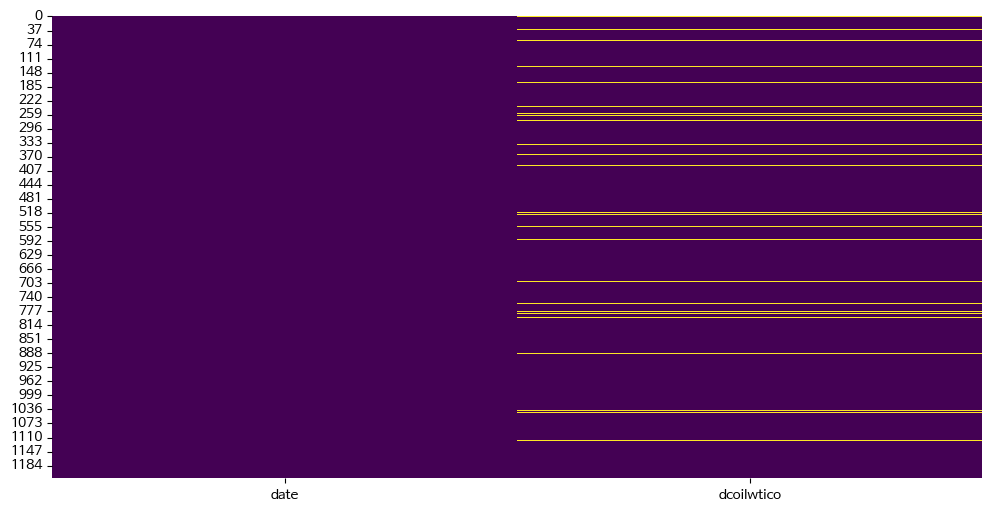

In [13]:
plt.figure(figsize=(12,6))
sns.heatmap(oil.isnull(),cbar=False,cmap='viridis')
plt.show()

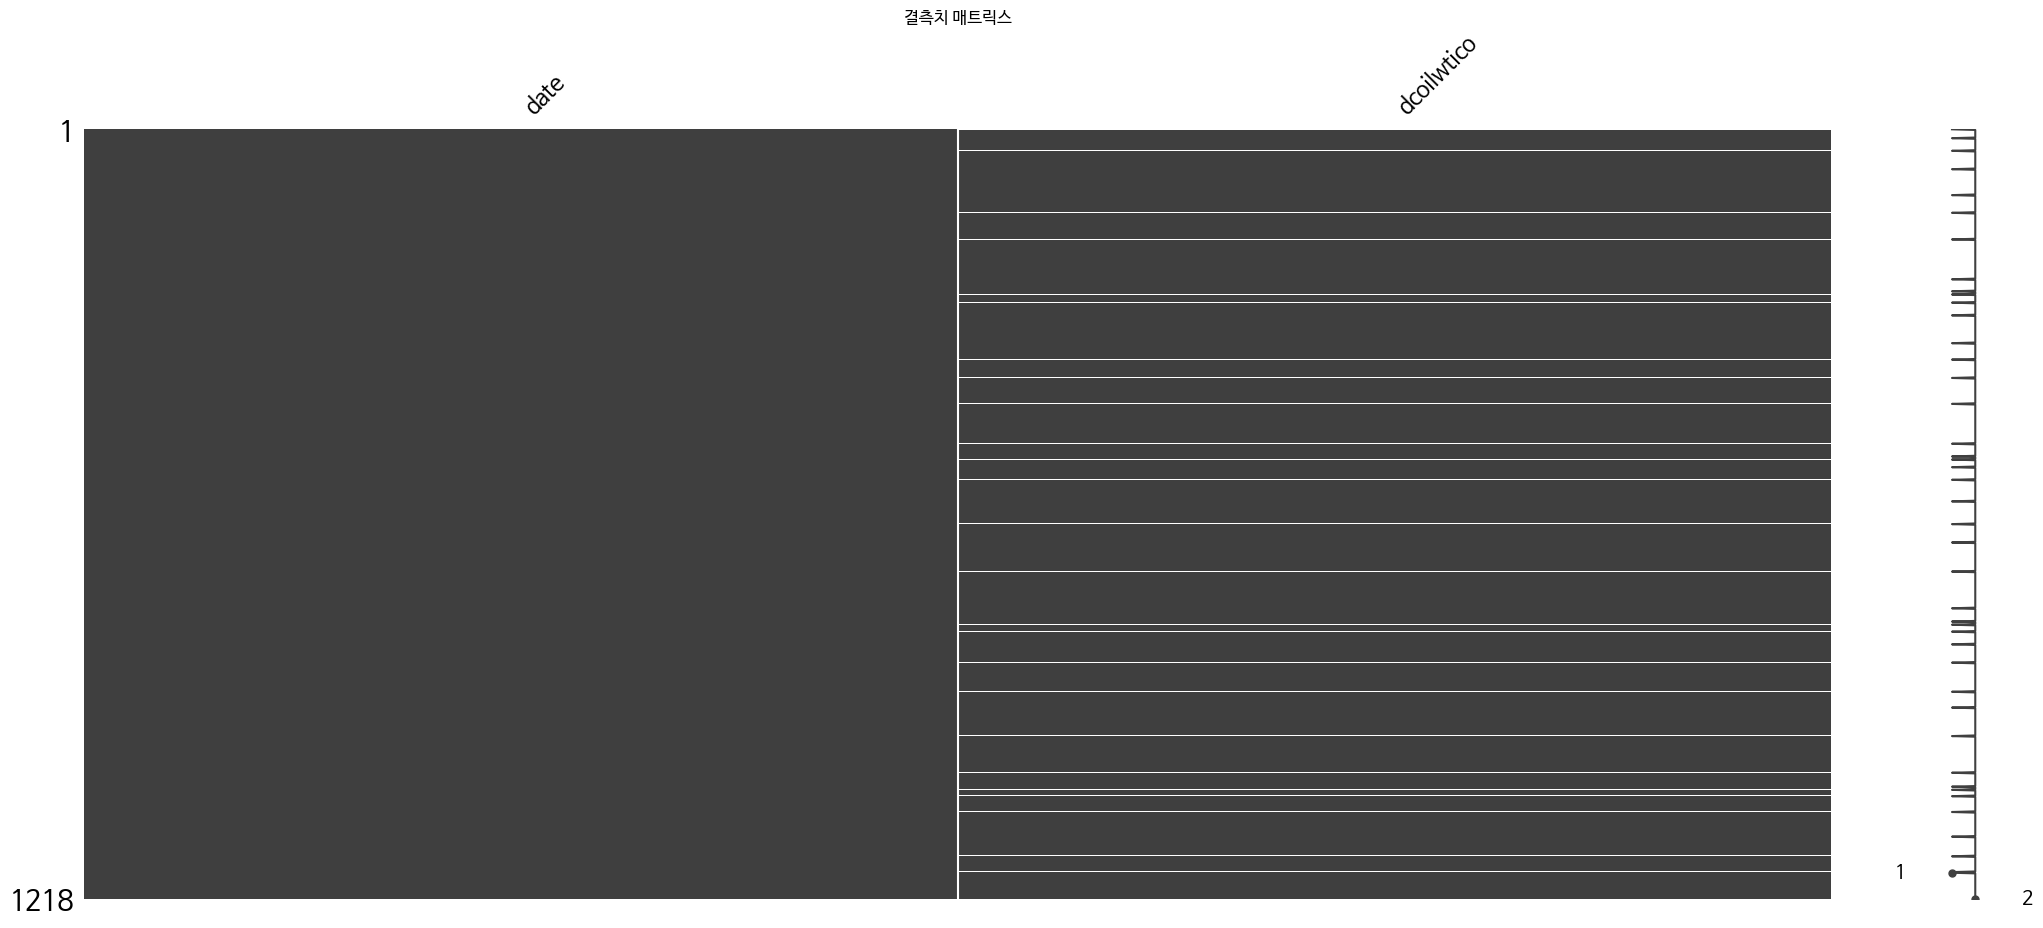

In [14]:
msno.matrix(oil)
plt.title('결측치 매트릭스')
plt.show()

In [15]:
oil['date']=pd.to_datetime(oil['date'])
print(oil.info())

holidays_events['date']=pd.to_datetime(holidays_events['date'])
train['date']=pd.to_datetime(train['date'])
transactions['date']=pd.to_datetime(transactions['date'])


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        1218 non-null   datetime64[ns]
 1   dcoilwtico  1175 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 19.2 KB
None


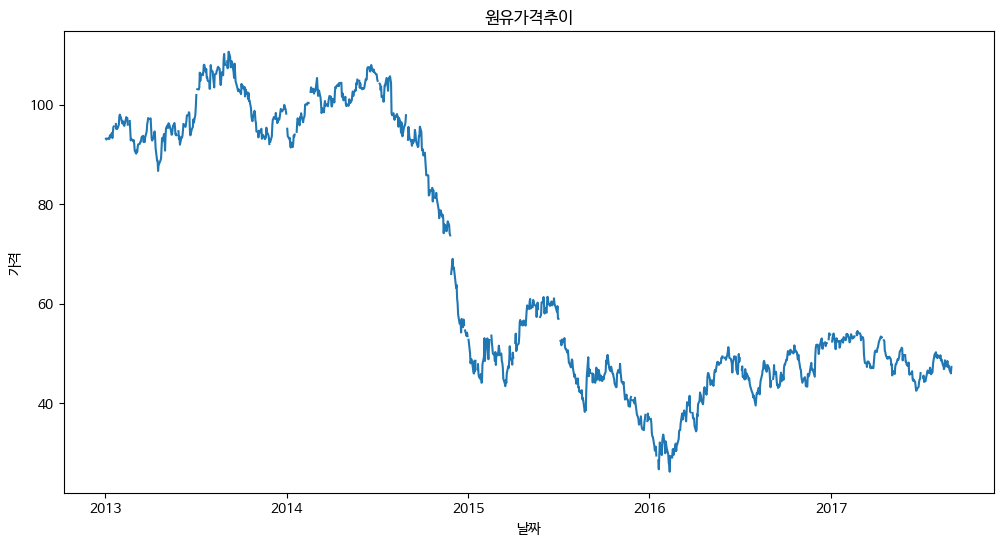

In [16]:
plt.figure(figsize=(12,6))
plt.plot(oil['date'],oil['dcoilwtico'])
plt.title('원유가격추이')
plt.xlabel('날짜')
plt.ylabel('가격')
plt.show()

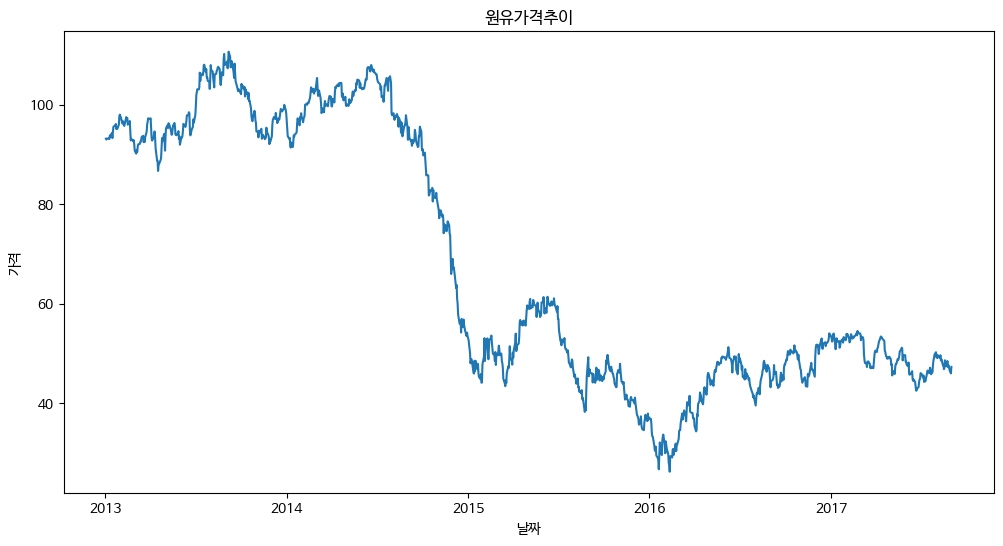

In [17]:
oil['dcoilwtico']=oil['dcoilwtico'].interpolate(method='linear')
plt.figure(figsize=(12,6))
plt.plot(oil['date'],oil['dcoilwtico'])
plt.title('원유가격추이')
plt.xlabel('날짜')
plt.ylabel('가격')
plt.show()

In [18]:
family_bound=train.groupby('family')['sales'].apply(lambda x: x.quantile(0.75)+1.5*(x.quantile(0.75)-x.quantile(0.25
                                                               )))
print(family_bound)

family
AUTOMOTIVE                      17.000000
BABY CARE                        0.000000
BEAUTY                          12.500000
BEVERAGES                     6452.000000
BOOKS                            0.000000
BREAD/BAKERY                  1336.500000
CELEBRATION                     30.000000
CLEANING                      2500.000000
DAIRY                         1926.500000
DELI                           633.335375
EGGS                           467.000000
FROZEN FOODS                   380.959127
GROCERY I                     8639.500000
GROCERY II                      69.000000
HARDWARE                         5.000000
HOME AND KITCHEN I              70.000000
HOME AND KITCHEN II             52.500000
HOME APPLIANCES                  2.500000
HOME CARE                      682.500000
LADIESWEAR                      22.500000
LAWN AND GARDEN                 20.000000
LINGERIE                        22.000000
LIQUOR,WINE,BEER               252.000000
MAGAZINES                  

In [28]:
train['upper_bound']=train['family'].map(family_bound)
train['is_outlier']=train['sales']>train['upper_bound']
print(train.head())
print(train['is_outlier'].sum())

   id       date  store_nbr      family  sales  onpromotion  upper_bound  \
0   0 2013-01-01          1  AUTOMOTIVE    0.0            0         17.0   
1   1 2013-01-01          1   BABY CARE    0.0            0          0.0   
2   2 2013-01-01          1      BEAUTY    0.0            0         12.5   
3   3 2013-01-01          1   BEVERAGES    0.0            0       6452.0   
4   4 2013-01-01          1       BOOKS    0.0            0          0.0   

   is_outlier  
0       False  
1       False  
2       False  
3       False  
4       False  
200274


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


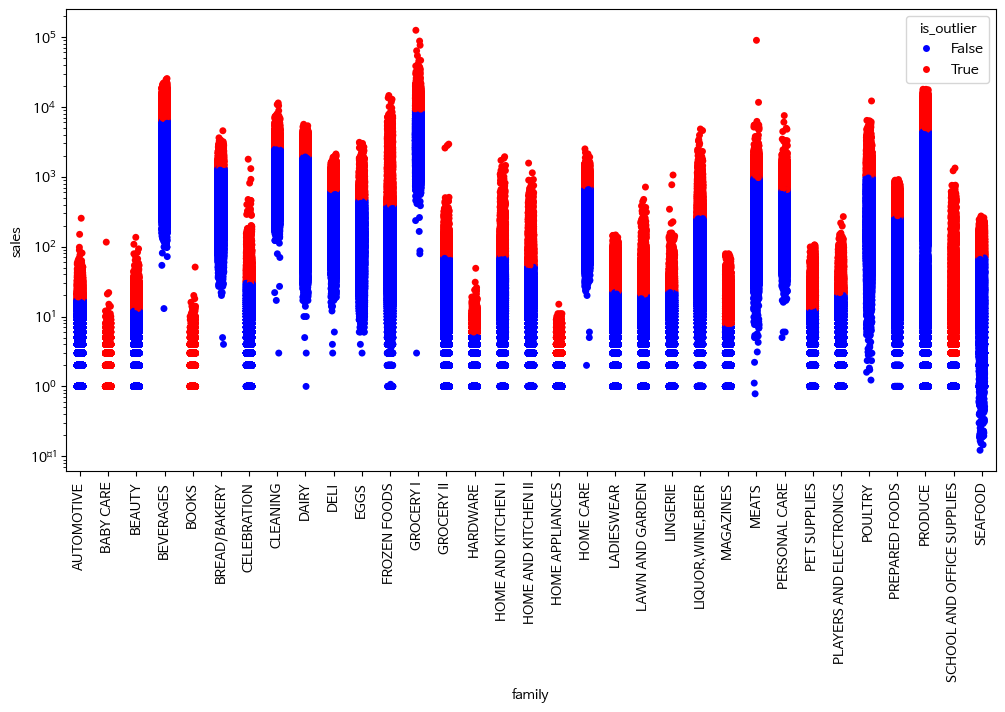

In [29]:
plt.figure(figsize=(12,6))
sns.stripplot(x='family',y='sales',hue=train['is_outlier'],
              data=train,palette={False:"blue",True:'red'})
plt.xticks(rotation=90)
plt.yscale('log')
plt.show()

In [30]:
train_cleaned=train.copy()
train_cleaned.loc[train['is_outlier'],'sales']=train.loc[train['is_outlier'],'upper_bound']
changed_count=train['sales'] !=train_cleaned['sales']

In [40]:
train_cleaned['dayofweek']=train_cleaned['date'].dt.dayofweek
day_sales=train_cleaned.groupby('dayofweek')['sales'].mean().reset_index()
day_sales['dayofweek']=day_sales['dayofweek'].map({0:"월",1:"화",2:"수",3:"목",
                                                   4:"금",5:"토",6:"일"})
print(day_sales)

  dayofweek       sales
0         월  328.242266
1         화  308.638456
2         수  311.235515
3         목  276.728659
4         금  307.129527
5         토  390.314264
6         일  402.156827


Text(0, 0.5, '평균판매량')

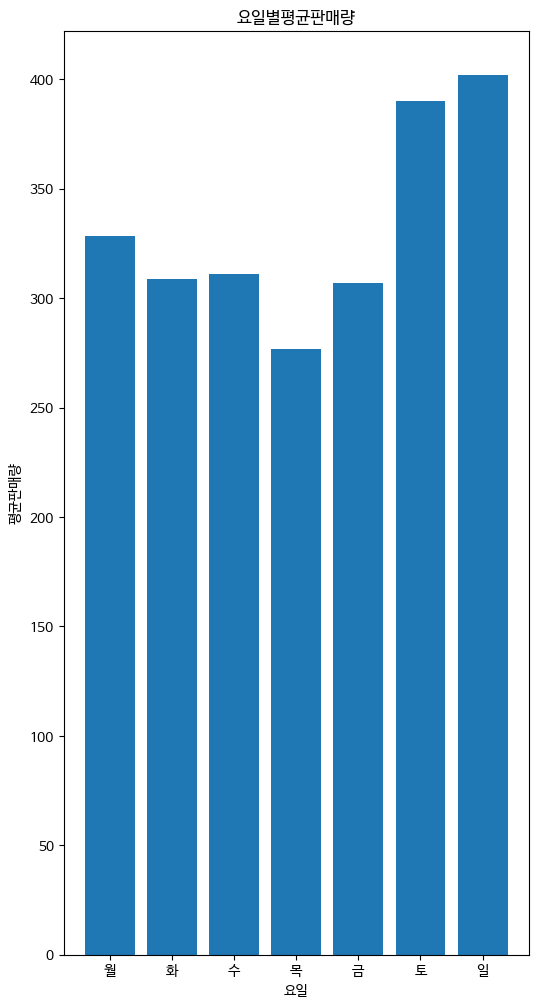

In [42]:
plt.figure(figsize=(6,12))
plt.bar(day_sales['dayofweek'],day_sales['sales'])
plt.title('요일별평균판매량')
plt.xlabel('요일')
plt.ylabel('평균판매량')

Text(0, 0.5, '평균판매량')

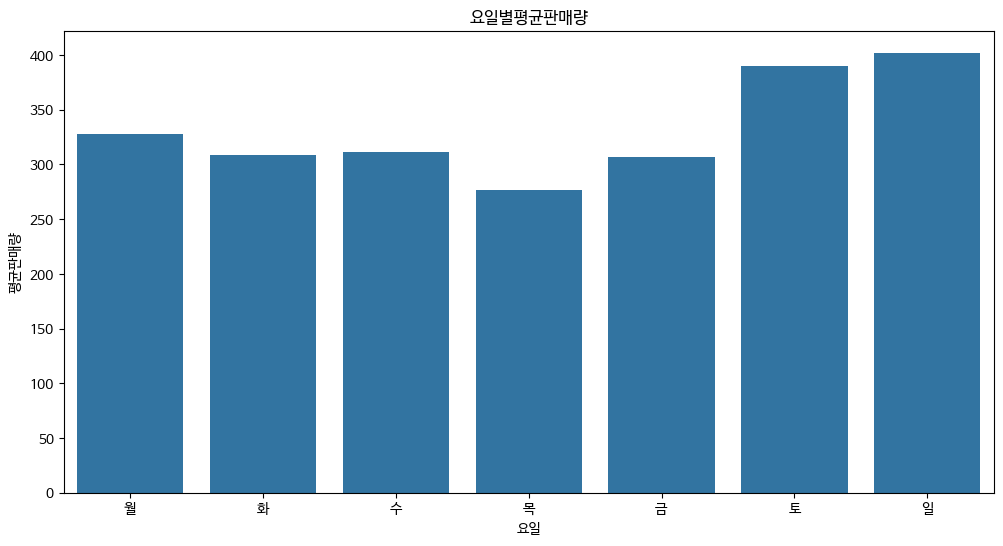

In [45]:
plt.figure(figsize=(12,6))
sns.barplot(x='dayofweek',y='sales',data=day_sales)
plt.title('요일별평균판매량')
plt.xlabel('요일')
plt.ylabel('평균판매량')

In [50]:
print(train_cleaned.shape)

(3000888, 9)


In [47]:
train_merge1=pd.merge(train_cleaned,transactions,
                      on=['date','store_nbr'],
                      how='left')
print(train_merge1)

              id       date  store_nbr                      family     sales  \
0              0 2013-01-01          1                  AUTOMOTIVE     0.000   
1              1 2013-01-01          1                   BABY CARE     0.000   
2              2 2013-01-01          1                      BEAUTY     0.000   
3              3 2013-01-01          1                   BEVERAGES     0.000   
4              4 2013-01-01          1                       BOOKS     0.000   
...          ...        ...        ...                         ...       ...   
3000883  3000883 2017-08-15          9                     POULTRY   438.133   
3000884  3000884 2017-08-15          9              PREPARED FOODS   154.553   
3000885  3000885 2017-08-15          9                     PRODUCE  2419.729   
3000886  3000886 2017-08-15          9  SCHOOL AND OFFICE SUPPLIES     2.500   
3000887  3000887 2017-08-15          9                     SEAFOOD    16.000   

         onpromotion  upper_bound  is_o

In [53]:
print(oil.columns.tolist())

['date', 'dcoilwtico']


In [52]:
train_merge2=pd.merge(train_merge1,stores,
                      on=['store_nbr'],
                      how='left')

In [59]:
train_merge3=pd.merge(train_merge2,oil,
                      on=['date'],
                      how='left')

print(train_merge3.head(1000))
print(oil.head(50))

      id       date  store_nbr        family  sales  onpromotion  upper_bound  \
0      0 2013-01-01          1    AUTOMOTIVE    0.0            0    17.000000   
1      1 2013-01-01          1     BABY CARE    0.0            0     0.000000   
2      2 2013-01-01          1        BEAUTY    0.0            0    12.500000   
3      3 2013-01-01          1     BEVERAGES    0.0            0  6452.000000   
4      4 2013-01-01          1         BOOKS    0.0            0     0.000000   
..   ...        ...        ...           ...    ...          ...          ...   
995  995 2013-01-01         37  BREAD/BAKERY    0.0            0  1336.500000   
996  996 2013-01-01         37   CELEBRATION    0.0            0    30.000000   
997  997 2013-01-01         37      CLEANING    0.0            0  2500.000000   
998  998 2013-01-01         37         DAIRY    0.0            0  1926.500000   
999  999 2013-01-01         37          DELI    0.0            0   633.335375   

     is_outlier  dayofweek 

In [60]:
print(oil.isnull().sum())

date          0
dcoilwtico    1
dtype: int64
